In [48]:
# Import libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from textblob import TextBlob # to understand the meaning of the sentences
from wordcloud import WordCloud

In [49]:
# Load the dataset
file = pd.read_csv("Sentiment_Analysis.csv")

file.head(8)

,Sentences
0,The product's exceptional quality and performa...
1,Poor customer support and the product's subpar...
2,The service met standard requirements without ...
3,Outstanding customer service accompanied the p...
4,The product's failure to meet basic requiremen...
5,The service provided met basic needs without n...
6,Remarkable product quality and performance exc...
7,Poor customer service and a faulty product led...


In [50]:
# Define the sentences analysis functions

def get_sentiment(text):
    meaning = TextBlob(text)

    if meaning.sentiment.polarity > 0: 
        return "positive"
        
    elif meaning.sentiment.polarity < 0:
        return "negative"
        
    else:
        return " neutral" 


In [51]:
file["Sentiment"] = file["Sentences"].apply(get_sentiment)

In [52]:
file.head()

,Sentences,Sentiment
0,The product's exceptional quality and performa...,positive
1,Poor customer support and the product's subpar...,negative
2,The service met standard requirements without ...,positive
3,Outstanding customer service accompanied the p...,positive
4,The product's failure to meet basic requiremen...,negative


In [53]:
file.to_excel("Sentiment_Analysis_sh.xlsx", index = False)

In [54]:
# Filter only negative reviews

negative_reviews = file[file ["Sentiment"] == "negative"]

In [55]:
negative_reviews.head(10)

,Sentences,Sentiment
1,Poor customer support and the product's subpar...,negative
4,The product's failure to meet basic requiremen...,negative
7,Poor customer service and a faulty product led...,negative
8,"The service provided was average, meeting mini...",negative
13,Dreadful customer support coupled with a defec...,negative
16,Severe product shortcomings led to considerabl...,negative
17,"The service was standard, meeting basic needs ...",negative
19,Disappointing product quality and poor custome...,negative
20,"The service provided was average, meeting basi...",negative


In [56]:
#combine all negative sentences into one string

negative_para = " ".join(negative_reviews["Sentences"])
print(negative_para )


Poor customer support and the product's subpar performance led to frustration and disappointment, regretting the purchase entirely. The product's failure to meet basic requirements resulted in immense inconvenience and frustration, causing regret over the purchase. Poor customer service and a faulty product led to significant inconvenience and frustration, resulting in regret over the purchase decision. The service provided was average, meeting minimum requirements without standout features, resulting in a standard user experience. Dreadful customer support coupled with a defective product caused immense frustration and disappointment, regretting the purchase. Severe product shortcomings led to considerable dissatisfaction and regret over the purchase due to a lack of promised functionality. The service was standard, meeting basic needs without noteworthy features, resulting in an average user experience without extremes. Disappointing product quality and poor customer service resulted

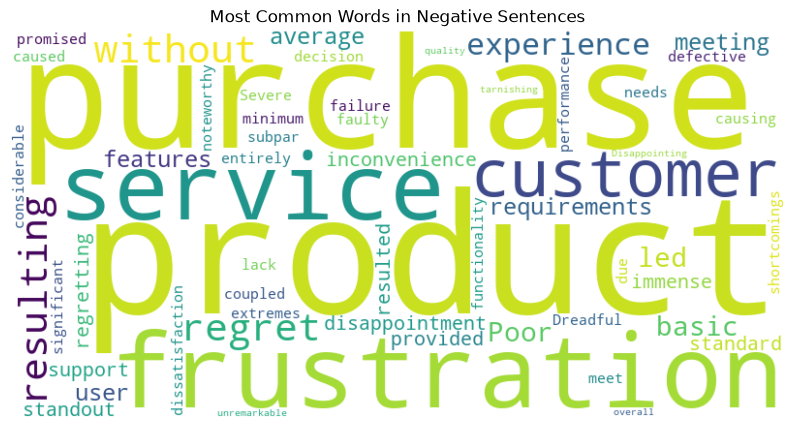

In [60]:
# create the Word Cloud for negative_para

wordcloud = WordCloud(width = 800 ,height = 400, background_color="white").generate(negative_para)

# plot the word cloud

plt.figure(figsize=(10,6))
plt.imshow(wordcloud,interpolation='bilinear')
plt.title("Most Common Words in Negative Sentences")
plt.axis("off")
plt.show()
